# Nº 06 et Nº 07 · La dérivée et le gradient

*θ Théta, le Machine Learning, une notion à la fois.*

La dérivée mesure la pente en un point. Le gradient rassemble les pentes de tous les réglages. On les calcule
de deux façons : avec la formule, et en mesurant un tout petit déplacement.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. La pente, par un petit déplacement

Pour J(a) = a², la dérivée vaut 2a. Le rapport (J(a + h) − J(a)) / h s'en approche quand h diminue.

In [2]:
def j(a):
    return a**2


a = 2
for h in (1, 0.1, 0.01, 0.001):
    print(f"h = {h:<6} : hausse ÷ h = {(j(a + h) - j(a)) / h:.3f}")

assert abs((j(a + 1e-6) - j(a)) / 1e-6 - 2 * a) < 1e-4

h = 1      : hausse ÷ h = 5.000
h = 0.1    : hausse ÷ h = 4.100
h = 0.01   : hausse ÷ h = 4.010
h = 0.001  : hausse ÷ h = 4.001


## 2. Le signe de la pente

Pente négative : J baisse quand a augmente. Pente positive : J monte. Pente nulle : le point est plat.
Cela ne vaut que pour un petit déplacement.

a = -2 : pente = -4
a = +0 : pente = +0
a = +2 : pente = +4


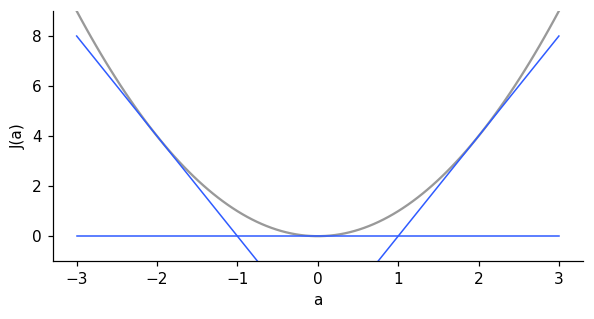

In [3]:
for point in (-2, 0, 2):
    print(f"a = {point:+d} : pente = {2 * point:+d}")

grille = np.linspace(-3, 3, 100)
plt.figure(figsize=(5.5, 3))
plt.plot(grille, j(grille), color="0.6")
for point in (-2, 0, 2):
    plt.plot(grille, j(point) + 2 * point * (grille - point), color="#2F5BFF", linewidth=1)
plt.ylim(-1, 9)
plt.xlabel("a")
plt.ylabel("J(a)")
plt.tight_layout()

## 3. Le gradient : une pente par réglage

Avec deux réglages, J(a, b) = a² + 3b². On fixe l'un et on dérive selon l'autre : (2a ; 6b).

In [4]:
def j2(a, b):
    return a**2 + 3 * b**2


def gradient(a, b):
    return np.array([2 * a, 6 * b])


def gradient_numerique(a, b, h=1e-6):
    return np.array([(j2(a + h, b) - j2(a - h, b)) / (2 * h), (j2(a, b + h) - j2(a, b - h)) / (2 * h)])


point = (2.0, 1.0)
print("formule :", gradient(*point))
print("mesuré  :", np.round(gradient_numerique(*point), 6))
assert np.allclose(gradient(*point), gradient_numerique(*point), atol=1e-5)

formule : [4. 6.]
mesuré  : [4. 6.]


## 4. Le gradient pointe vers la plus forte hausse

Parmi toutes les directions, un petit pas le long du gradient fait le plus monter J.

In [5]:
angles = np.linspace(0, 2 * np.pi, 720, endpoint=False)
directions = np.c_[np.cos(angles), np.sin(angles)]
hausses = np.array([j2(*(np.array(point) + 1e-4 * d)) - j2(*point) for d in directions])
meilleure = directions[hausses.argmax()]
attendue = gradient(*point) / np.linalg.norm(gradient(*point))
print("direction de la plus forte hausse :", np.round(meilleure, 3))
print("direction du gradient             :", np.round(attendue, 3))
assert np.allclose(meilleure, attendue, atol=0.01)

direction de la plus forte hausse : [0.552 0.834]
direction du gradient             : [0.555 0.832]


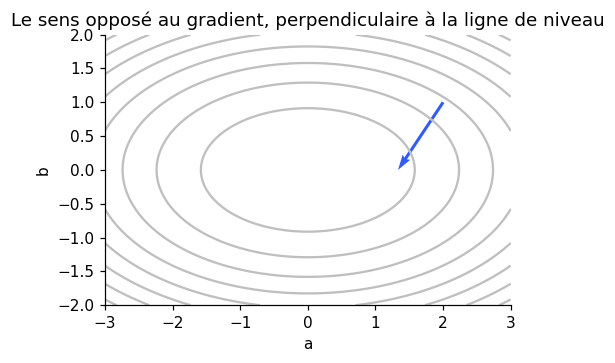

In [6]:
A, B = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-2, 2, 200))
plt.figure(figsize=(5.5, 3.4))
plt.contour(A, B, j2(A, B), levels=8, colors="0.75")
plt.quiver(*point, *(-gradient(*point) / 6), color="#2F5BFF", angles="xy", scale_units="xy", scale=1)
plt.gca().set_aspect("equal")
plt.title("Le sens opposé au gradient, perpendiculaire à la ligne de niveau")
plt.xlabel("a")
plt.ylabel("b")
plt.tight_layout()

## À vous

1. Vérifiez le gradient de J(a, b) = a² + ab + b² par les deux méthodes.
2. Que devient le rapport hausse ÷ h si h vaut 1e-15 ? Pourquoi ?

**Sources** : Deep Learning Book, D2L, Machine Learning Crash Course. Les références complètes figurent dans le
premier commentaire des épisodes.